# **Visualisasi Data**

Visualisasi data merupakan proses menyajikan data dalam bentuk grafis atau visual seperti diagram, grafik, dan tabel sehingga data lebih mudah dipahami dan dianalisis.

Visualisasi data bertujuan mempermudah dalam melihat pola, tren, perbandingan, serta hubungan antarvariabel dalam suatu dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan file data_transaksi_2025.csv sudah diunggah ke Google Colab.
ds = pd.read_csv('/content/data_transaksi_2025.csv')

* Pandas (pd): untuk membaca dan mengolah data dalam bentuk tabel.
* NumPy (np): untuk melakukan perhitungan numerik.
* Matplotlib (plt): untuk membuat grafik dan visualisasi data.
* Seaborn (sns): untuk membuat visualisasi data statistik dengan tampilan yang lebih menarik.

## Bagian 1 : Penjualan Per Bulan 2025 **(Line Chart)**

In [2]:
ds['tanggal'] = pd.to_datetime(ds['tanggal'])

penjualan_bulanan = ds[ds['status'] == 'SELESAI'].groupby(
    ds['tanggal'].dt.month
)['pendapatan'].sum()

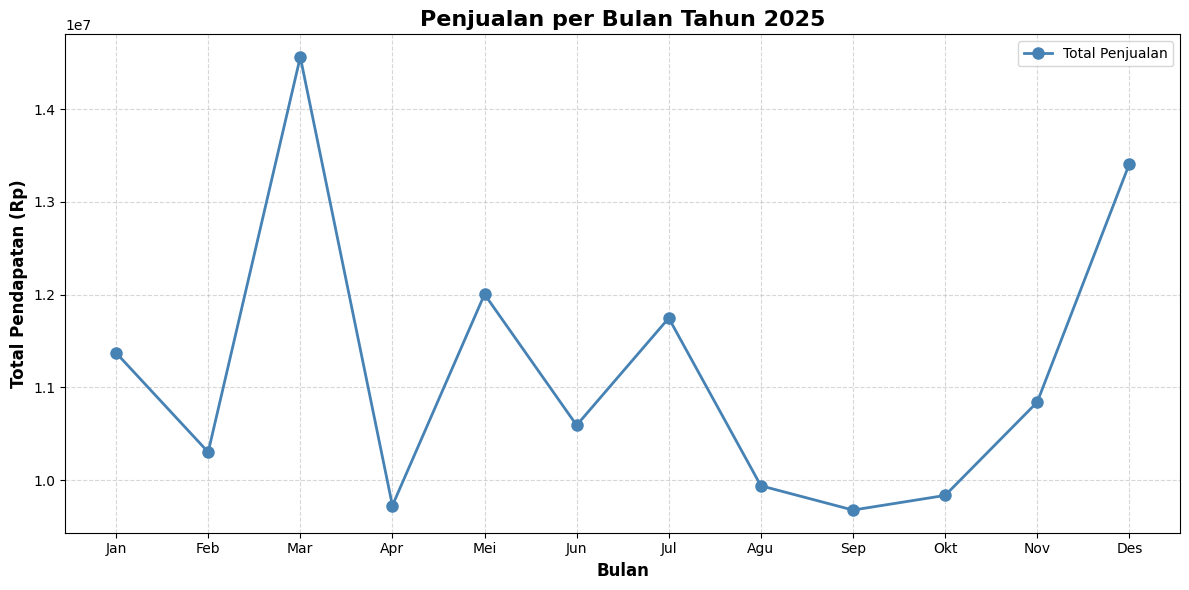

In [3]:
plt.figure(figsize=(12, 6))

plt.plot(
    penjualan_bulanan.index,
    penjualan_bulanan.values,
    color='steelblue',
    marker='o',
    markersize=8,
    linewidth=2,
    linestyle='-',
    label='Total Penjualan'
)

plt.title('Penjualan per Bulan Tahun 2025',
          fontsize=16, fontweight='bold')
plt.xlabel('Bulan', fontsize=12, fontweight='bold')
plt.ylabel('Total Pendapatan (Rp)', fontsize=12, fontweight='bold')

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
     'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Line Chart adalah jenis visualisasi data yang digunakan untuk menampilkan perubahan atau perkembangan data dari waktu ke waktu dengan menghubungkan titik-titik menggunakan garis.

Pada dataset transaksi tahun 2025, grafik ini digunakan untuk menampilkan total pendapatan penjualan setiap bulan, mulai dari Januari hingga Desember. Tujuannya untuk mengetahui perkembangan penjualan serta melihat bulan dengan pendapatan tertinggi dan terendah.

## Bagian 2 : 10 Produk Terlaris Tahun 2025 **(Bar Chart)**

In [4]:
produk_terlaris = ds[ds['status'] == 'SELESAI'].groupby(
    'kode_produk'
)['jumlah'].sum().sort_values(ascending=False).head(10)

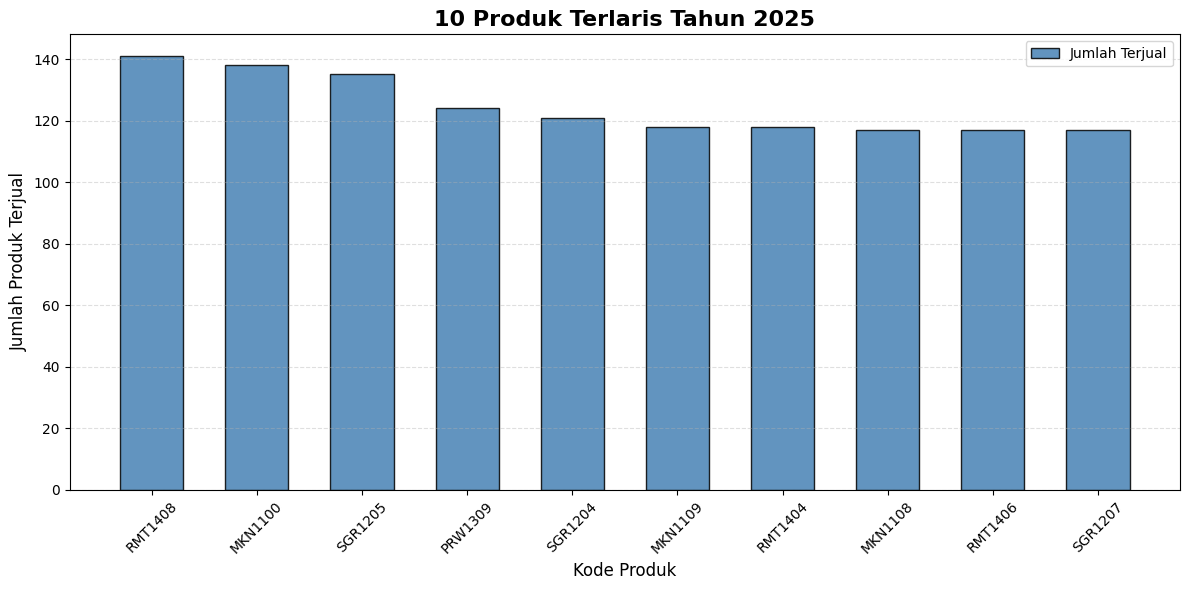

In [5]:
plt.figure(figsize=(12, 6))

plt.bar(
    produk_terlaris.index,
    produk_terlaris.values,
    color='steelblue',
    width=0.6,
    edgecolor='black',
    linewidth=1,
    alpha=0.85
)

plt.title('10 Produk Terlaris Tahun 2025',
          fontsize=16, fontweight='bold')
plt.xlabel('Kode Produk', fontsize=12)
plt.ylabel('Jumlah Produk Terjual', fontsize=12)

plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(['Jumlah Terjual'])

plt.tight_layout()
plt.show()

Bar Chart adalah jenis visualisasi data yang digunakan untuk membandingkan nilai atau jumlah antar kategori menggunakan batang.

Pada dataset transaksi tahun 2025, grafik ini digunakan untuk menampilkan 10 produk dengan jumlah penjualan tertinggi. Tujuannya untuk mengetahui produk yang paling banyak dibeli pelanggan berdasarkan jumlah produk terjual.

## Bagian 3 : proporsi transaksi berhasil vs gagal/cancel tahun 2025

In [6]:
transaksi = ds[ds['tahun'] == 2025]

status_transaksi = transaksi['status'].value_counts()

persentase = status_transaksi / status_transaksi.sum() * 100

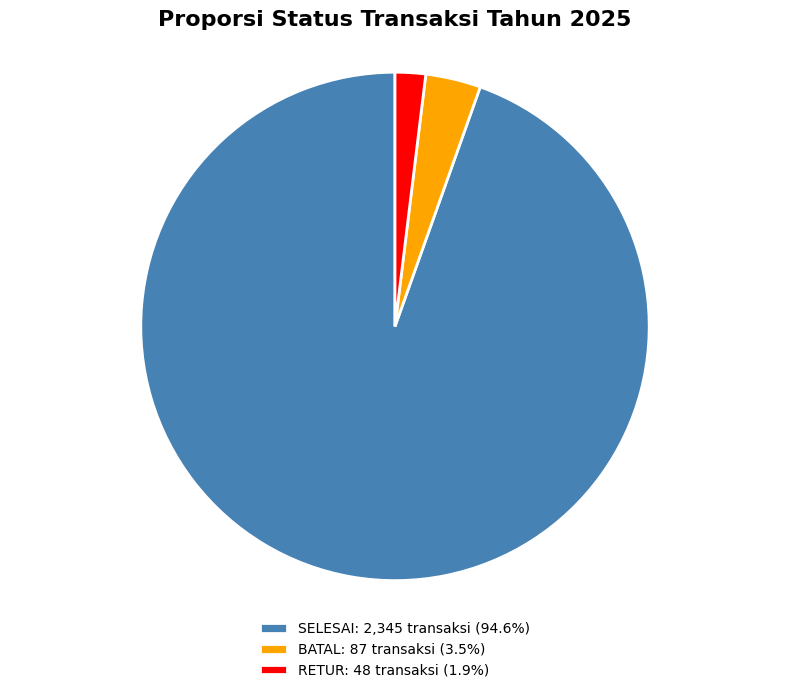

In [7]:
warna = ['steelblue', 'orange', 'red']

label_legend = [
    f'{status}: {jumlah:,} transaksi ({persen:.1f}%)'
    for status, jumlah, persen in zip(
        status_transaksi.index,
        status_transaksi.values,
        persentase.values
    )
]

fig, ax = plt.subplots(figsize=(8, 7))

wedges, _ = ax.pie(
    status_transaksi.values,
    colors=warna,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

ax.set_title(
    'Proporsi Status Transaksi Tahun 2025',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.legend(
    wedges,
    label_legend,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.15),
    frameon=False,
    fontsize=10
)

ax.axis('equal')
plt.tight_layout()
plt.show()

Pie Chart adalah jenis visualisasi data yang digunakan untuk menampilkan perbandingan proporsi atau persentase setiap kategori terhadap keseluruhan data.

Pada dataset transaksi tahun 2025, grafik ini digunakan untuk menampilkan persentase transaksi berdasarkan status `SELESAI`, `BATAL`, dan `RETUR`. Tujuannya untuk mengetahui perbandingan jumlah transaksi berdasarkan statusnya.

## Bagian 4 : Hubungan Jumlah Beli Dengan Diskon **(Scatter Plot)**

In [8]:
transaksi = ds[
    (ds['tahun'] == 2025) &
    (ds['status'] == 'SELESAI')
].copy()

diskon = sorted(transaksi['diskon_persen'].unique())

rata_rata = transaksi.groupby(
    'diskon_persen'
)['jumlah'].mean()

np.random.seed(42)

posisi = transaksi['diskon_persen'].map(
    {nilai: i for i, nilai in enumerate(diskon)}
)

jitter = np.random.uniform(
    -0.18, 0.18, len(transaksi)
)

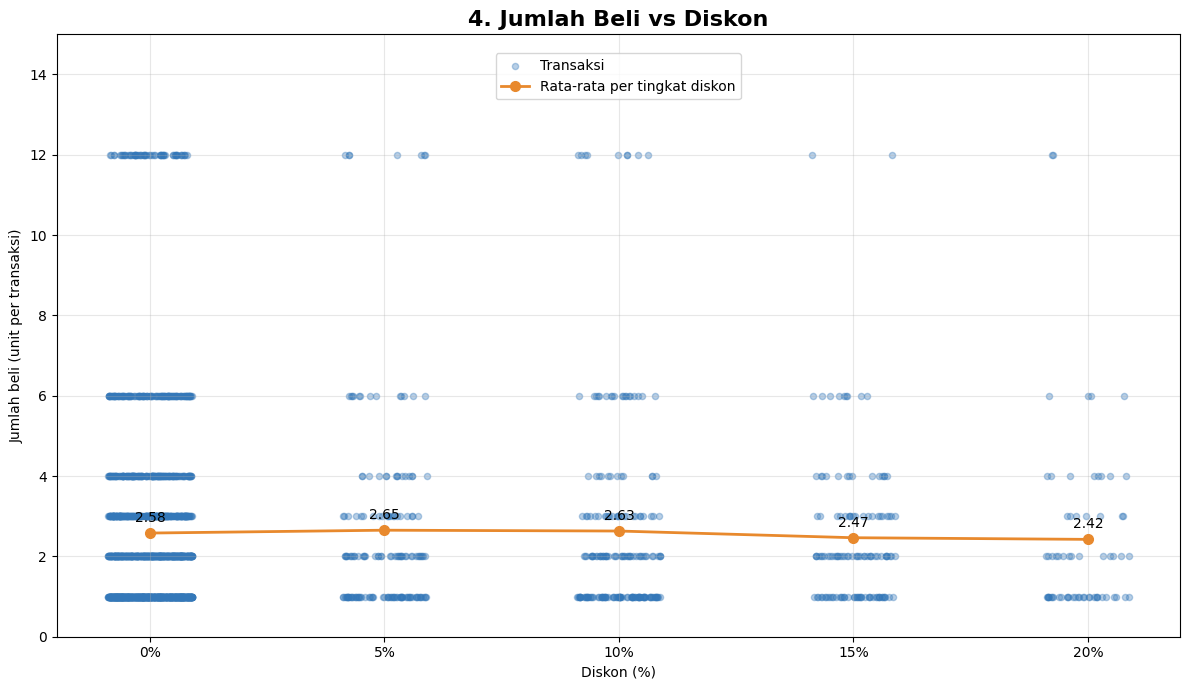

In [9]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    posisi + jitter,
    transaksi['jumlah'],
    color='#3478B9',
    alpha=0.35,
    s=20,
    label='Transaksi'
)

ax.plot(
    range(len(diskon)),
    rata_rata.values,
    color='#E8892D',
    marker='o',
    linewidth=2,
    markersize=7,
    label='Rata-rata per tingkat diskon'
)

for i, nilai in enumerate(rata_rata.values):
    ax.annotate(
        f'{nilai:.2f}',
        (i, nilai),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=10
    )

ax.set_title(
    '4. Jumlah Beli vs Diskon',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Diskon (%)')
ax.set_ylabel('Jumlah beli (unit per transaksi)')

ax.set_xticks(range(len(diskon)))
ax.set_xticklabels([f'{d}%' for d in diskon])

ax.set_ylim(0, 15)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 0.98),
    fontsize=10
)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Scatter Plot adalah jenis visualisasi data yang digunakan untuk menunjukkan hubungan antara dua variabel numerik melalui kumpulan titik-titik pada grafik.

Pada dataset transaksi tahun 2025, grafik ini digunakan untuk melihat hubungan antara persentase diskon dengan jumlah produk yang dibeli pelanggan. Titik biru menunjukkan transaksi, sedangkan garis oranye menunjukkan rata-rata jumlah pembelian pada setiap tingkat diskon.

Tujuannya untuk mengetahui pola hubungan antara pemberian diskon dengan jumlah pembelian pelanggan.